# UTS Graf Sains Data
## Python Driver Neo4j dan Rekomendasi (dataset RetailRocket)

**Rivaldi Rizky Taufani / 23031554010 / Graf Sains Data 2023 B** 

**Pembagian periode data (individu)**

| Fold | Mulai | Hingga |
|---|---|---|
| Training (P1) | 01/05/2015 | 01/07/2015 |
| Testing (P2) | 10/07/2015 | 25/07/2015 |

**Ringkasan alur kerja**

1. Menyiapkan lingkungan (venv) dan menguji koneksi Python ke Neo4j lewat tutorial driver.
2. Memuat dataset RetailRocket (`events.csv`), memfilter periode P1 dan P2, lalu menyimpannya ke CSV.
3. Mengimpor data P1 ke Neo4j sebagai graf: simpul `Visitor` dan `Item`, relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`.
4. Soal 2.1: komposisi subgraph, VSM user dan item, pemilihan proyeksi, perhitungan similarity, dan penulisan hasilnya kembali ke graf.
5. Soal 2.2: rekomendasi KNN untuk satu user acak, lalu evaluasi Hit@5 dan NDCG@5 terhadap data P2.

**Lingkungan:** Python dalam virtual environment `myenv` dengan paket `neo4j` (versi 5.x), `pandas`, `numpy`, `scipy`, `scikit-learn`, `networkx`, `matplotlib`, dan `tqdm`. Fungsi `execute_query` pada tutorial membutuhkan driver `neo4j` versi 5.x, sehingga baris `neo4j==4.2.1` pada `requirements.txt` di soal tidak dipakai.

> **Catatan keamanan:** password Neo4j pada cell koneksi sudah diganti menjadi `PASSWORD_ANDA`. Isi dengan password milik sendiri saat menjalankan ulang, dan jangan mengunggah password asli ke GitHub.

## 1. Tugas Pendahuluan
### 1.2 Tutorial penggunaan driver Neo4j

Cell berikut menghubungkan Python ke Neo4j dengan `GraphDatabase.driver`, membuat simpul `Person` beserta relasi `KNOWS` memakai `MERGE` (tidak membuat duplikat bila dijalankan ulang), lalu mencetak teman Arthur. Output **Terhubung!** diikuti tiga nama (Guinevere, Lancelot, Merlin) menandakan koneksi dan penulisan data berhasil.

In [ ]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "admin123") 


def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )


def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])


with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Terhubung!")
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Terhubung!
Guinevere
Lancelot
Merlin


#### Jawaban Pertanyaan Pendahuluan (Checkpoint)

1. Apa nama database yang digunakan pada tutorial ini? 
Database yang dipakai bernama neo4j, terlihat dari parameter database_="neo4j" di fungsi add_friend dan print_friends.

2. Sebutkan akses lain yang dapat digunakan mengakses database lain dalam 1 instance!
    a. :use namadb di Neo4j Browser untuk berpindah database aktif.
    b. USE namadb di awal query Cypher, misalnya USE namadb MATCH (n) RETURN n.
    c. SHOW DATABASES untuk melihat daftar database yang ada.
    d. CREATE DATABASE namadb untuk membuat database baru (DDL).
    e. Di Python, driver.session(database="namadb") atau execute_query(..., database_="namadb").

3. Apa jenis graf pertemanan yang telah dibuat di sini? 
Grafnya adalah graf berarah (directed graph). Hubungan -[:KNOWS]-> punya arah dari Arthur ke temannya, jadi Arthur "mengenal" Guinevere, Lancelot, dan Merlin, tapi belum tentu sebaliknya. Bentuknya mirip bintang dengan Arthur di tengah. Semua simpulnya berlabel Person dan relasinya satu jenis saja (KNOWS) tanpa bobot.

### 1.3 Impor data RetailRocket ke Neo4j

Sumber data: RetailRocket (Roman Zykov, Kaggle). File yang dipakai adalah `events.csv`.

#### Memuat data dan mengubah timestamp

Kolom `timestamp` berformat unix epoch dalam **milidetik**, jadi diubah dengan `pd.to_datetime(..., unit="ms")` menjadi kolom `waktu` agar bisa difilter per tanggal.

Hasilnya: **2.756.101 baris** dengan rentang waktu **3 Mei 2015 (03:00) sampai 18 September 2015 (02:59)**. Periode P1 dan P2 yang ditetapkan berada di dalam rentang ini.

In [4]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["waktu"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df.shape)
print("Rentang data:", df["waktu"].min(), "->", df["waktu"].max())

(2756101, 6)
Rentang data: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000


#### Struktur dan deskripsi fitur

| Kolom | Tipe | Arti | Catatan |
|---|---|---|---|
| `timestamp` | int64 | Waktu kejadian (unix epoch) | Satuan milidetik |
| `visitorid` | int64 | ID unik pengunjung | Menjadi simpul `Visitor` |
| `event` | teks | Jenis interaksi | `view`, `addtocart`, `transaction` |
| `itemid` | int64 | ID unik produk | Menjadi simpul `Item` |
| `transactionid` | float64 | ID transaksi | Hanya terisi pada event `transaction` |

Dari output: terdapat **1.407.580 visitor unik** dan **235.061 item unik** pada data penuh. Kolom `transactionid` kosong (NaN) pada 2.733.644 baris, sehingga hanya 22.457 baris yang terisi, yaitu baris event `transaction` sesuai deskripsi soal. Event `view` mendominasi (2.664.312 baris).

**Pemetaan ke graf:** `view` menjadi relasi `VIEWED`, `addtocart` menjadi `ADDED_TO_CART`, dan `transaction` menjadi `BOUGHT`.

In [7]:
df = pd.read_csv("data/events.csv")

print(df.dtypes)
print(df.head())
print(df.isna().sum())
print("Visitor unik:", df["visitorid"].nunique())
print("Item unik   :", df["itemid"].nunique())
print(df["event"].value_counts())

timestamp          int64
visitorid          int64
event                str
itemid             int64
transactionid    float64
dtype: object
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64
Visitor unik: 1407580
Item unik   : 235061
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


## 2. Soal UTS
### 2.1 Wrangling dan EDA

#### No. 1 — Filter dua periode waktu

- **P1 (training):** 01/05/2015 sampai 01/07/2015
- **P2 (testing):** 10/07/2015 sampai 25/07/2015

Asumsi yang dipakai:
- Tanggal akhir bersifat **inklusif** (sampai pukul 23:59:59 pada hari tersebut).
- Zona waktu tidak dikonversi (hasil `pd.to_datetime` apa adanya).
- Data asli baru dimulai 3 Mei 2015, sehingga P1 secara praktis dimulai pada 3 Mei.

Hasil filter:

| | Jumlah baris | view | addtocart | transaction |
|---|---|---|---|---|
| P1 (training) | 1.221.809 | 1.182.016 | 29.944 | 9.849 |
| P2 (testing) | 360.049 | 348.338 | 8.869 | 2.842 |

Di kedua periode, event `view` sekitar 97% dari seluruh baris, sedangkan `transaction` sangat sedikit.

In [ ]:
def filter_periode(df, mulai, hingga):
    batas_awal = pd.Timestamp(mulai)
    batas_akhir = pd.Timestamp(hingga) + pd.Timedelta(days=1)
    return df[(df["waktu"] >= batas_awal) & (df["waktu"] < batas_akhir)]

df_p1 = filter_periode(df, "2015-05-01", "2015-07-01")   # training
df_p2 = filter_periode(df, "2015-07-10", "2015-07-25")   # testing

print("P1 training:", df_p1.shape, df_p1["waktu"].min(), "->", df_p1["waktu"].max())
print("P2 testing :", df_p2.shape, df_p2["waktu"].min(), "->", df_p2["waktu"].max())
print(df_p1["event"].value_counts())
print(df_p2["event"].value_counts())

P1 training: (1221809, 6) 2015-05-03 03:00:04.384000 -> 2015-07-01 23:59:57.285000
P2 testing : (360049, 6) 2015-07-10 00:00:04.611000 -> 2015-07-25 23:59:57.739000
event
view           1182016
addtocart        29944
transaction       9849
Name: count, dtype: int64
event
view           348338
addtocart        8869
transaction      2842
Name: count, dtype: int64


#### No. 2 — Menyimpan hasil filter ke CSV

Hasil filter disimpan ke `data/events_p1_train.csv` dan `data/events_p2_test.csv`. Hanya kolom asli yang disimpan (tanpa kolom bantu `waktu`) supaya formatnya sama dengan `events.csv` dan kompatibel dengan kode impor.

P1 diimpor ke Neo4j sebagai graf. P2 **tidak** diimpor; P2 dipakai pada soal 2.2 sebagai kunci jawaban untuk evaluasi.

In [6]:
kolom = ["timestamp", "visitorid", "event", "itemid", "transactionid"]

df_p1[kolom].to_csv("data/events_p1_train.csv", index=False)
df_p2[kolom].to_csv("data/events_p2_test.csv", index=False)
print("Tersimpan.")

Tersimpan.


#### Impor P1 ke Neo4j (soal 1.3)

Cell ini membuat koneksi dan dua *constraint* unik: `Visitor.visitorId` dan `Item.itemId`. Constraint membuat `MERGE` mencari simpul lewat indeks, sehingga impor jauh lebih cepat dan tidak membuat simpul ganda.

Penyesuaian dari kode contoh pada soal:
1. Fungsi `create_constraints` dilengkapi (tidak diberikan pada soal).
2. Tiga jenis relasi dibuat dengan `FOREACH` + `CASE` pada satu query, bukan `CALL { ... UNION ALL ... }`. Hasilnya setara: setiap baris menghasilkan tepat satu relasi sesuai nilai `event`.
3. `transactionid` dibersihkan dengan `float → int → teks`, sehingga tertulis `"4000"` dan bukan `"4000.0"`.
4. Data dibaca per *batch* 10.000 baris.

> Password pada cell ini adalah placeholder `PASSWORD_ANDA`.

In [8]:
from neo4j import GraphDatabase
from tqdm import tqdm
import pandas as pd

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "PASSWORD_ANDA")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

Fungsi `import_batch` menerima satu batch baris. Untuk setiap baris: `MERGE` simpul `Visitor` dan `Item`, lalu membuat relasi sesuai `event`. Relasi dibuat dengan `CREATE` karena satu visitor bisa berinteraksi berkali-kali dengan item yang sama, dan setiap kejadian disimpan lengkap dengan `timestamp`-nya.

In [9]:
def import_batch(tx, batch):
    tx.run("""
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i))
    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))
    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp,
                             transactionId: row.transactionid}]->(i))
    """, batch=batch)

#### Menjalankan impor

Impor selesai dalam **123 batch** dengan waktu sekitar **1 menit 22 detik**.

> Jalankan cell ini **sekali saja**. Relasi dibuat dengan `CREATE`, sehingga menjalankannya ulang akan menggandakan relasi.

In [10]:
csv_path = "data/events_p1_train.csv"
batch_size = 10000
total_rows = 1221809
total_chunks = (total_rows // batch_size) + 1

with driver.session() as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_path, chunksize=batch_size)
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].apply(
            lambda x: "" if pd.isna(x) else str(int(x))
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Mengimpor Batch Data: 100%|██████████| 123/123 [01:22<00:00,  1.49it/s]

Proses impor berhasil.


#### Verifikasi hasil impor

Jumlah relasi di graf harus sama dengan jumlah event pada P1. Hasilnya cocok:

| Relasi | Di graf | Event di P1 |
|---|---|---|
| `VIEWED` | 1.182.016 | 1.182.016 |
| `ADDED_TO_CART` | 29.944 | 29.944 |
| `BOUGHT` | 9.849 | 9.849 |

Simpul: **616.913 Visitor** dan **164.206 Item**. Relasi `KNOWS` (3) adalah sisa tutorial Arthur, bukan bagian dari dataset.

In [11]:
with driver.session() as session:
    print(session.run("MATCH (v:Visitor) RETURN count(v) AS n").single()["n"])
    print(session.run("MATCH (i:Item) RETURN count(i) AS n").single()["n"])
    for r in session.run("MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS n"):
        print(r["tipe"], r["n"])

616913
164206
KNOWS 3
VIEWED 1182016
ADDED_TO_CART 29944
BOUGHT 9849


#### Membersihkan sisa tutorial

Simpul `Person` dari tutorial dihapus agar komposisi subgraph di bawah hanya berisi data RetailRocket.

In [12]:
driver.execute_query("MATCH (p:Person) DETACH DELETE p", database_="neo4j")

EagerResult(records=[], summary=<neo4j._work.summary.ResultSummary object at 0x0000014C3BB704D0>, keys=[])

#### No. 3 — Komposisi subgraph (jenis dan jumlah simpul)

**Penjelasan Cypher**

```cypher
MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah
ORDER BY jumlah DESC
```

- `MATCH (n)` mengambil semua simpul di graf.
- `labels(n)` mengembalikan daftar label tiap simpul, misalnya `["Visitor"]`.
- `UNWIND ... AS label` memecah daftar itu menjadi satu baris per label.
- `RETURN label, count(*)` mengelompokkan per label lalu menghitung jumlahnya. Di Cypher, pengelompokan terjadi otomatis pada kolom non-agregat, jadi tidak perlu `GROUP BY`.
- `ORDER BY jumlah DESC` mengurutkan dari yang terbanyak.

Query kedua, `MATCH ()-[r]->()` dengan `type(r)`, menghitung relasi per jenisnya. Python API yang dipakai adalah `driver.execute_query(...)`, hasilnya diubah menjadi DataFrame pandas.

In [13]:
q_simpul = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah
ORDER BY jumlah DESC
"""

records, _, _ = driver.execute_query(q_simpul, database_="neo4j")
df_simpul = pd.DataFrame([r.data() for r in records])
df_simpul

,label,jumlah
0,Visitor,616913
1,Item,164206


In [14]:
q_relasi = """
MATCH ()-[r]->()
RETURN type(r) AS tipe_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

records, _, _ = driver.execute_query(q_relasi, database_="neo4j")
df_relasi = pd.DataFrame([r.data() for r in records])
df_relasi

,tipe_relasi,jumlah
0,VIEWED,1182016
1,ADDED_TO_CART,29944
2,BOUGHT,9849


**Hasil komposisi subgraph**

| Jenis simpul | Jumlah |
|---|---|
| Visitor | 616.913 |
| Item | 164.206 |

| Jenis relasi | Jumlah |
|---|---|
| VIEWED | 1.182.016 |
| ADDED_TO_CART | 29.944 |
| BOUGHT | 9.849 |

Subgraph ini berbentuk **graf bipartit**: `Visitor` hanya terhubung ke `Item`, tidak pernah Visitor–Visitor atau Item–Item. Rasionya sekitar 3,7 visitor per item (616.913 / 164.206). Sifat bipartit inilah yang mendasari proyeksi pada soal no. 6.

#### No. 4 dan 5 — Vector Space Modelling (VSM)

VSM mengubah tiap simpul menjadi **vektor angka** agar kemiripannya bisa dihitung.

- **VSM User:** satu vektor per Visitor, dimensinya adalah Item. Isinya kekuatan interaksi user dengan tiap item.
- **VSM Item:** satu vektor per Item, dimensinya adalah User.

Keduanya berasal dari **satu matriks yang sama** (baris = user, kolom = item), tinggal dibaca per baris atau per kolom.

**Bobot interaksi:** `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5. Alasannya, aksi yang lebih dekat ke pembelian menunjukkan minat yang lebih kuat. Bobot dijumlahkan per pasangan (visitor, item).

Hasilnya **941.621 pasangan (user, item) unik**. Angka ini lebih kecil dari 1.221.809 event P1 karena beberapa event dari pasangan yang sama dijumlahkan menjadi satu sel.

In [15]:
q_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor,
       i.itemId   AS item,
       sum(CASE type(r)
             WHEN 'VIEWED' THEN 1
             WHEN 'ADDED_TO_CART' THEN 3
             WHEN 'BOUGHT' THEN 5
           END) AS bobot
"""

records, _, _ = driver.execute_query(q_vsm, database_="neo4j")
df_ui = pd.DataFrame([r.data() for r in records])
print(df_ui.shape)
df_ui.head()

(941621, 3)


,visitor,item,bobot
0,257597,355908,1
1,981382,355908,1
2,1102250,355908,1
3,76757,355908,1
4,979686,355908,1


**Matriks sparse.** `pd.factorize` memberi nomor baris dan kolom pada ID user dan item (kamus baliknya disimpan di `user_ids` dan `item_ids`), lalu dibentuk `csr_matrix`.

Matriks penuh berukuran 616.913 × 164.206, sekitar 10¹¹ sel, atau sekitar 800 GB bila disimpan sebagai `float64`. Padahal hanya 941.621 sel yang terisi, sehingga bentuk sparse hanya membutuhkan belasan MB dan wajib dipakai.

In [16]:
from scipy.sparse import csr_matrix

user_codes, user_ids = pd.factorize(df_ui["visitor"])
item_codes, item_ids = pd.factorize(df_ui["item"])

X = csr_matrix(
    (df_ui["bobot"].values, (user_codes, item_codes)),
    shape=(len(user_ids), len(item_ids))
)
print("Shape X (user x item):", X.shape)

Shape X (user x item): (616913, 164206)


#### No. 4 — Karakteristik VSM User

In [19]:
import numpy as np
n_user, n_item = X.shape
print("=== VSM USER ===")
print("Jumlah vektor (user)  :", n_user)
print("Dimensi tiap vektor   :", n_item, "(= jumlah item)")
print("Shape                 :", X.shape)
print("Sel terisi (nnz)      :", X.nnz)
print("Density               :", X.nnz / (n_user * n_item))
print("Sparsity (%)          :", 100 * (1 - X.nnz / (n_user * n_item)))

item_per_user = X.getnnz(axis=1)
print("Rata-rata item/user   :", item_per_user.mean())
print("Median item/user      :", np.median(item_per_user))
print("Maks item/user        :", item_per_user.max())
print("% user hanya 1 item   :", 100 * (item_per_user == 1).mean())

=== VSM USER ===
Jumlah vektor (user)  : 616913
Dimensi tiap vektor   : 164206 (= jumlah item)
Shape                 : (616913, 164206)
Sel terisi (nnz)      : 941621
Density               : 9.295295304185574e-06
Sparsity (%)          : 99.99907047046959
Rata-rata item/user   : 1.5263432607190965
Median item/user      : 1.0
Maks item/user        : 1314
% user hanya 1 item   : 79.54200997547466


**Karakteristik VSM User**

| Karakteristik | Nilai |
|---|---|
| Jumlah vektor (user) | 616.913 |
| Dimensi tiap vektor (item) | 164.206 |
| Shape | 616.913 × 164.206 |
| Sel terisi (nnz) | 941.621 |
| Density / sparsity | 9,30 × 10⁻⁶ / 99,999% |
| Item per user (rata-rata / median / maks) | 1,53 / 1 / 1.314 |
| User yang hanya berinteraksi dengan 1 item | 79,54% |

Vektor user sangat jarang terisi: hampir 80% user hanya menyentuh satu item, sehingga hanya ada satu elemen non-nol pada vektornya. Ada user ekstrem dengan 1.314 item.

#### No. 5 — Karakteristik VSM Item

VSM Item adalah transpos dari matriks yang sama (`X.T`).

In [21]:
XT = X.T.tocsr()
print("=== VSM ITEM ===")
print("Jumlah vektor (item)  :", XT.shape[0])
print("Dimensi tiap vektor   :", XT.shape[1], "(= jumlah user)")
print("Shape                 :", XT.shape)
print("Sel terisi (nnz)      :", XT.nnz)

user_per_item = XT.getnnz(axis=1)
print("Rata-rata user/item   :", user_per_item.mean())
print("Median user/item      :", np.median(user_per_item))
print("Maks user/item        :", user_per_item.max())
print("% item hanya 1 user   :", 100 * (user_per_item == 1).mean())

=== VSM ITEM ===
Jumlah vektor (item)  : 164206
Dimensi tiap vektor   : 616913 (= jumlah user)
Shape                 : (164206, 616913)
Sel terisi (nnz)      : 941621
Rata-rata user/item   : 5.734388511991035
Median user/item      : 2.0
Maks user/item        : 1095
% item hanya 1 user   : 42.179335712458744


**Karakteristik VSM Item**

| Karakteristik | Nilai |
|---|---|
| Jumlah vektor (item) | 164.206 |
| Dimensi tiap vektor (user) | 616.913 |
| Shape | 164.206 × 616.913 |
| Sel terisi (nnz) | 941.621 (sama dengan VSM User) |
| User per item (rata-rata / median / maks) | 5,73 / 2 / 1.095 |
| Item yang hanya disentuh 1 user | 42,18% |

Vektor item sedikit lebih "tebal" daripada vektor user (median 2 user dibanding 1 item), tetapi tetap berdistribusi *long-tail*: sedikit item sangat populer, banyak item hanya disentuh segelintir user.

**Plot networkx (sampel).** Graf penuh tidak mungkin digambar, jadi diambil sampel: 8 item dengan user terbanyak dan 30 user acak (`seed=42`) yang menyentuh minimal 2 dari item tersebut. Titik biru adalah user, titik oranye adalah item, dan garis adalah interaksi.

Matplotlib is building the font cache; this may take a moment.


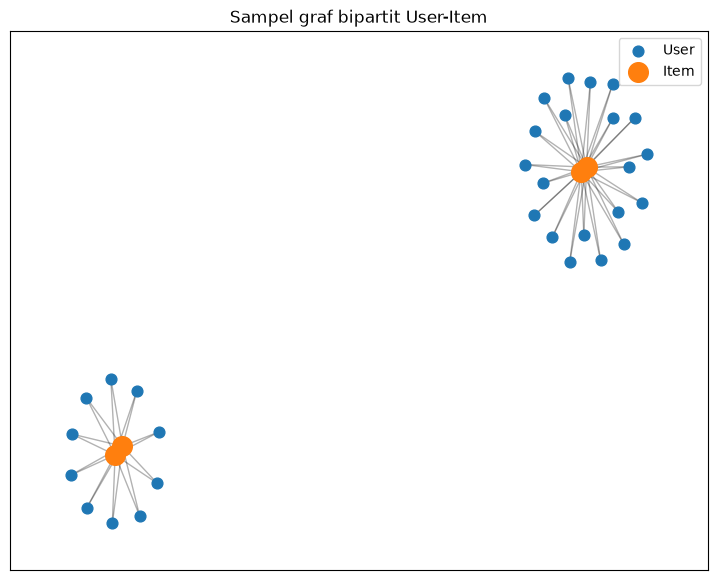

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

top_items = df_ui.groupby("item").size().nlargest(8).index
sub = df_ui[df_ui["item"].isin(top_items)]
cnt = sub.groupby("visitor").size()
kandidat = cnt[cnt >= 2].index.to_numpy()
user_sampel = rng.choice(kandidat, size=min(30, len(kandidat)), replace=False)
sub = sub[sub["visitor"].isin(user_sampel)]

G = nx.Graph()
users = sub["visitor"].unique()
items = sub["item"].unique()
G.add_nodes_from([f"U{u}" for u in users], bipartite=0)
G.add_nodes_from([f"I{i}" for i in items], bipartite=1)
G.add_edges_from((f"U{r.visitor}", f"I{r.item}") for r in sub.itertuples())

pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(9, 7))
nx.draw_networkx_nodes(G, pos, nodelist=[f"U{u}" for u in users],
                       node_color="tab:blue", node_size=60, label="User")
nx.draw_networkx_nodes(G, pos, nodelist=[f"I{i}" for i in items],
                       node_color="tab:orange", node_size=200, label="Item")
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.legend()
plt.title("Sampel graf bipartit User-Item")
plt.show()

**Pembacaan plot:** sampel terlihat sebagai dua kelompok yang terpisah. Pada tiap kelompok, beberapa item (oranye, saling bertumpuk sehingga tidak bisa dihitung satu per satu dari gambar) berada di tengah dan dikelilingi user (biru) yang terhubung ke item-item itu. Tidak ada garis user–user atau item–item, sesuai sifat graf bipartit. Gambar ini hanya sampel kecil, bukan seluruh graf.

Plot yang sama dipakai untuk VSM User (tiap titik biru adalah vektor user yang menunjuk ke item) dan VSM Item (tiap titik oranye adalah vektor item yang ditunjuk user).

#### No. 6 — Proyeksi mana yang lebih baik?

- **Proyeksi User (user–user):** dua user terhubung bila pernah berinteraksi dengan item yang sama. Matriksnya `X · Xᵀ`.
- **Proyeksi Item (item–item):** dua item terhubung bila pernah disentuh user yang sama. Matriksnya `Xᵀ · X`.

Cell berikut hanya **menghitung ukuran** proyeksi (tanpa membentuk matriks hasil perkaliannya) agar aman bagi memori. Perkiraan jumlah sisi adalah batas atas, karena dua simpul yang berbagi banyak tetangga terhitung berkali-kali.

In [ ]:
deg_user = X.getnnz(axis=1).astype(np.int64)    # jumlah item per user
deg_item = XT.getnnz(axis=1).astype(np.int64)   # jumlah user per item

# Perkiraan batas atas jumlah sisi proyeksi
sisi_item_proj = int((deg_user * (deg_user - 1) // 2).sum())
sisi_user_proj = int((deg_item * (deg_item - 1) // 2).sum())

# Simpul yang punya minimal 1 tetangga di proyeksi
item_terhubung = np.unique(X[deg_user >= 2].indices).size
user_terhubung = np.unique(XT[deg_item >= 2].indices).size

print("=== Proyeksi Item (item-item) ===")
print("Jumlah simpul          :", XT.shape[0])
print("Simpul punya tetangga  :", item_terhubung, f"({100*item_terhubung/XT.shape[0]:.1f}%)")
print("Perkiraan sisi (maks)  :", sisi_item_proj)
print("Ukuran matriks dense   :", f"{XT.shape[0]**2*8/1e9:.0f} GB (float64)")

print("\n=== Proyeksi User (user-user) ===")
print("Jumlah simpul          :", X.shape[0])
print("Simpul punya tetangga  :", user_terhubung, f"({100*user_terhubung/X.shape[0]:.1f}%)")
print("Perkiraan sisi (maks)  :", sisi_user_proj)
print("Ukuran matriks dense   :", f"{X.shape[0]**2*8/1e9:.0f} GB (float64)")

=== Proyeksi Item (item-item) ===
Jumlah simpul          : 164206
Simpul punya tetangga  : 99105 (60.4%)
Perkiraan sisi (maks)  : 10336371
Ukuran matriks dense   : 216 GB (float64)

=== Proyeksi User (user-user) ===
Jumlah simpul          : 616913
Simpul punya tetangga  : 572230 (92.8%)
Perkiraan sisi (maks)  : 20681357
Ukuran matriks dense   : 3045 GB (float64)


**Perbandingan kedua proyeksi**

| | Proyeksi Item | Proyeksi User |
|---|---|---|
| Jumlah simpul | 164.206 | 616.913 |
| Simpul yang punya tetangga | 99.105 (60,4%) | 572.230 (92,8%) |
| Perkiraan sisi (batas atas) | 10.336.371 | 20.681.357 |
| Ukuran matriks dense | 216 GB | 3.045 GB |

**Kesimpulan: proyeksi item dipilih.**

- **Efisiensi:** proyeksi item jauh lebih ringan, dengan simpul sekitar 3,8 kali lebih sedikit, sisi sekitar dua kali lebih sedikit, dan ukuran matriks dense sekitar 14 kali lebih kecil. Keduanya tetap harus disimpan sebagai sparse.
- **Kekuatan sinyal:** 79,5% user hanya punya 1 item, sedangkan median item disentuh 2 user, jadi vektor item membawa informasi lebih banyak daripada vektor user.
- **Kecocokan dengan rekomendasi:** item-based KNN konsisten dengan proyeksi ini dan dipakai pada soal 2.2.
- **Kelemahan:** cakupan proyeksi item hanya 60,4%. Item tanpa tetangga tidak bisa dihitung kemiripannya, sedangkan proyeksi user mencakup 92,8% simpul. Cakupan user yang tinggi ini bisa menipu, karena banyak user hanya menjadi tetangga lewat satu item populer.

#### No. 7 — Perhitungan similarity pada proyeksi item

Similarity yang dipakai adalah **cosine**: `cos(a, b) = (a · b) / (‖a‖ ‖b‖)`. Tiap vektor item dinormalisasi (norma L2 = 1) sehingga dot product dua vektor langsung sama dengan cosine. Hanya baris untuk item acuan yang dihitung (bukan seluruh matriks), supaya hemat memori.

Cell-cell berikut sengaja dipertahankan sebagai **catatan proses**: beberapa percobaan penentuan item acuan sebelum mencapai hasil yang bermakna.

**Percobaan 1.** Item acuan dipilih acak (`seed=42`) dari item dengan minimal 20 user: item **49257**. Lima item termirip semuanya bernilai cosine **0,567962**, persis sama.

In [ ]:
from sklearn.preprocessing import normalize

Xn_item = normalize(XT, norm="l2", axis=1)

rng = np.random.default_rng(42)
kandidat = np.where(deg_item >= 20)[0]
ref_idx = int(rng.choice(kandidat))
ref_item_id = int(item_ids[ref_idx])

sim = (Xn_item @ Xn_item[ref_idx].T).toarray().ravel()
sim[ref_idx] = -1                   
top5 = np.argsort(-sim)[:5]

hasil = pd.DataFrame({
    "item_acuan": ref_item_id,
    "item_mirip": [int(x) for x in item_ids[top5]],
    "cosine": sim[top5],
})
hasil

,item_acuan,item_mirip,cosine
0,49257,132726,0.567962
1,49257,66946,0.567962
2,49257,455240,0.567962
3,49257,224079,0.567962
4,49257,399730,0.567962


**Diagnosa percobaan 1.** Ada **7 item** yang seri di nilai cosine tertinggi, dan kelima item tadi hanya dipilih dari tujuh itu. Semuanya hanya disentuh **1 user**, yaitu user yang juga menyentuh item acuan. Cosine tinggi tetapi hanya didukung satu orang, jadi belum bermakna.

In [24]:
maks = sim.max()
n_seri = int(np.isclose(sim, maks).sum())
print("Cosine tertinggi            :", maks)
print("Jumlah item dengan nilai itu:", n_seri)

users_ref = XT[ref_idx].indices
print("User yang menyentuh item acuan:", len(users_ref))

for j in top5:
    bersama = np.intersect1d(users_ref, XT[j].indices)
    print(int(item_ids[j]), "| total user:", XT[j].nnz, "| user bersama:", len(bersama))

Cosine tertinggi            : 0.5679618342470648
Jumlah item dengan nilai itu: 7
User yang menyentuh item acuan: 37
132726 | total user: 1 | user bersama: 1
66946 | total user: 1 | user bersama: 1
455240 | total user: 1 | user bersama: 1
224079 | total user: 1 | user bersama: 1
399730 | total user: 1 | user bersama: 1


**Percobaan 1b: tie-break yang jelas.** Urutan peringkat dibuat tetap: cosine, lalu jumlah user bersama, lalu `itemId`. Hasilnya masih sama lemahnya (`user_bersama` = 1 pada semua baris), tetapi kini bisa direproduksi.

In [ ]:
B = XT.copy()
B.data[:] = 1                                 
common = (B @ B[ref_idx].T).toarray().ravel()  

urut = np.lexsort((np.asarray(item_ids), -common, -sim)) 
top5 = urut[:5]

hasil = pd.DataFrame({
    "item_acuan": ref_item_id,
    "item_mirip": [int(x) for x in item_ids[top5]],
    "cosine": sim[top5],
    "user_bersama": common[top5],
})
hasil

,item_acuan,item_mirip,cosine,user_bersama
0,49257,4020,0.567962,1
1,49257,66946,0.567962,1
2,49257,132726,0.567962,1
3,49257,224079,0.567962,1
4,49257,343626,0.567962,1


**Percobaan 2: dukungan minimum.** Ditetapkan `MIN_BERSAMA = 3`: sebuah item hanya boleh menjadi kandidat bila minimal 3 user menyentuh item itu **dan** item acuan. Untuk acuan 49257, hanya **1 kandidat** yang lolos (item 336131, cosine 0,012, 5 user bersama), jadi acuan ini tidak punya tetangga yang bermakna.

In [26]:
MIN_BERSAMA = 3      # minimal user yang menyentuh kedua item

sim_f = sim.copy()
sim_f[common < MIN_BERSAMA] = -1
sim_f[ref_idx] = -1

urut = np.lexsort((np.asarray(item_ids), -common, -sim_f))
top5 = urut[:5]

hasil = pd.DataFrame({
    "item_acuan": ref_item_id,
    "item_mirip": [int(x) for x in item_ids[top5]],
    "cosine": sim_f[top5],
    "user_bersama": common[top5],
})
hasil = hasil[hasil["cosine"] > 0]
print("Kandidat yang lolos syarat:", int((sim_f > 0).sum()))
hasil

Kandidat yang lolos syarat: 1


,item_acuan,item_mirip,cosine,user_bersama
0,49257,336131,0.012043,5


**Percobaan 3: acuan dari item yang lebih ramai.** Fungsi `top_k_mirip` dibuat agar proses bisa diulang. Dari item dengan minimal 100 user (638 calon), terpilih item **418572** (101 user), tetapi **0 kandidat** lolos syarat. Jumlah user saja tidak menjamin sebuah item punya tetangga, karena sebagian besar user hanya menyentuh satu item.

In [ ]:

B = XT.copy()
B.data[:] = 1

def top_k_mirip(ref_idx, min_bersama=3, k=5):
    sim = (Xn_item @ Xn_item[ref_idx].T).toarray().ravel()
    common = (B @ B[ref_idx].T).toarray().ravel()
    sim[common < min_bersama] = -1
    sim[ref_idx] = -1
    n_lolos = int((sim > 0).sum())
    urut = np.lexsort((np.asarray(item_ids), -common, -sim))[:k]
    out = pd.DataFrame({
        "item_acuan": int(item_ids[ref_idx]),
        "item_mirip": [int(x) for x in item_ids[urut]],
        "cosine": sim[urut],
        "user_bersama": common[urut],
    })
    return out[out["cosine"] > 0], n_lolos

rng = np.random.default_rng(42)
kandidat_ref = np.where(deg_item >= 100)[0]
print("Jumlah calon acuan:", len(kandidat_ref))

ref_idx = int(rng.choice(kandidat_ref))
ref_item_id = int(item_ids[ref_idx])
print("Item acuan:", ref_item_id, "| user:", int(deg_item[ref_idx]))

hasil, n_lolos = top_k_mirip(ref_idx, min_bersama=3, k=5)
print("Kandidat yang lolos syarat:", n_lolos)
hasil

Jumlah calon acuan: 638
Item acuan: 418572 | user: 101
Kandidat yang lolos syarat: 0


,item_acuan,item_mirip,cosine,user_bersama


**Memilih acuan yang terbukti punya tetangga.** Untuk tiap calon acuan dihitung berapa item lain yang berbagi minimal 3 user. Hasilnya **546 dari 638** calon punya minimal 5 tetangga, jadi acuan 418572 tadi hanya kasus kurang beruntung.

In [ ]:
MIN_BERSAMA = 3
MIN_TETANGGA = 5      # acuan harus punya >= 5 tetangga yang lolos

cands = np.where(deg_item >= 100)[0]
C = (B[cands] @ B.T).tocoo()       

mask = (C.data >= MIN_BERSAMA) & (C.col != cands[C.row])
n_tetangga = np.bincount(C.row[mask], minlength=len(cands))

layak = cands[n_tetangga >= MIN_TETANGGA]
print("Calon acuan        :", len(cands))
print("Yang punya tetangga:", len(layak))

Calon acuan        : 638
Yang punya tetangga: 546


**Hasil final.** Acuan dipilih acak (`seed=42`) dari 546 item yang layak: item **420960** (150 user), dengan **501 kandidat** lolos syarat dukungan minimum.

In [29]:
rng = np.random.default_rng(42)
ref_idx = int(rng.choice(layak))
ref_item_id = int(item_ids[ref_idx])
print("Item acuan:", ref_item_id, "| user:", int(deg_item[ref_idx]))

hasil, n_lolos = top_k_mirip(ref_idx, min_bersama=MIN_BERSAMA, k=5)
print("Kandidat yang lolos syarat:", n_lolos)
hasil

Item acuan: 420960 | user: 150
Kandidat yang lolos syarat: 501


,item_acuan,item_mirip,cosine,user_bersama
0,420960,457045,0.268993,3
1,420960,283916,0.268089,37
2,420960,414654,0.265228,3
3,420960,174724,0.261426,3
4,420960,333792,0.232332,3


**Lima item termirip dengan item 420960**

| Item mirip | Cosine | User bersama |
|---|---|---|
| 457045 | 0,2690 | 3 |
| 283916 | 0,2681 | 37 |
| 414654 | 0,2652 | 3 |
| 174724 | 0,2614 | 3 |
| 333792 | 0,2323 | 3 |

Catatan: item 283916 berbagi **37 user** dengan acuan, tetapi cosine-nya hampir sama dengan item yang hanya berbagi 3 user. Cosine membagi dengan panjang vektor, sehingga item yang disentuh sedikit user bisa mendapat nilai tinggi walau user bersamanya sedikit. Ini keterbatasan yang perlu diingat saat membaca hasil.

#### No. 8 — Kondisi SEBELUM perhitungan similarity

Cell ini dijalankan **sebelum** relasi similarity ditulis. Jumlah relasi `SIMILAR_TO` adalah **0**. Neo4j menampilkan peringatan *"relationship type does not exist"*; itu bukan error, melainkan penanda bahwa tipe relasi `SIMILAR_TO` memang belum ada.

In [30]:
q_cek = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah"
rec, _, _ = driver.execute_query(q_cek, database_="neo4j")
print("Relasi SIMILAR_TO sebelum:", rec[0]["jumlah"])

records, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS jumlah ORDER BY jumlah DESC",
    database_="neo4j")
pd.DataFrame([r.data() for r in records])

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=13, offset=12>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 12, 'line': 1, 'column': 13}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah'


Relasi SIMILAR_TO sebelum: 0


,tipe,jumlah
0,VIEWED,1182016
1,ADDED_TO_CART,29944
2,BOUGHT,9849


#### No. 7b — Menulis nilai similarity ke graf

Kelima pasangan item ditulis sebagai relasi berarah `(acuan)-[:SIMILAR_TO]->(item mirip)`, dengan properti `cosine`, `user_bersama`, dan `min_bersama`. Memakai `MERGE` sehingga aman bila cell dijalankan ulang (tidak membuat relasi ganda).

In [31]:
pasangan = [
    {"item": int(r.item_mirip), "cosine": float(r.cosine), "user_bersama": int(r.user_bersama)}
    for r in hasil.itertuples()
]

def tulis_similarity(tx, ref_id, pasangan, min_bersama):
    tx.run("""
    UNWIND $pasangan AS p
    MATCH (a:Item {itemId: $ref_id})
    MATCH (b:Item {itemId: p.item})
    MERGE (a)-[s:SIMILAR_TO]->(b)
    SET s.cosine = p.cosine,
        s.user_bersama = p.user_bersama,
        s.min_bersama = $min_bersama
    """, ref_id=ref_id, pasangan=pasangan, min_bersama=min_bersama)

with driver.session() as session:
    session.execute_write(tulis_similarity, ref_item_id, pasangan, MIN_BERSAMA)
print("Similarity ditulis ke graf.")

Similarity ditulis ke graf.


#### No. 7a — Cypher untuk 5 record dengan similarity tertinggi

```cypher
MATCH (a:Item {itemId: $ref_id})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip,
       s.cosine AS cosine, s.user_bersama AS user_bersama
ORDER BY s.cosine DESC
LIMIT 5
```

Record acuan adalah item **420960**. `MATCH` mencari relasi `SIMILAR_TO` dari item acuan, `ORDER BY s.cosine DESC` mengurutkan dari similarity terbesar, dan `LIMIT 5` mengambil lima teratas. Hasilnya sama dengan tabel hasil perhitungan di Python, sehingga nilai similarity terbukti tersimpan di graf.

In [32]:
q_top5 = """
MATCH (a:Item {itemId: $ref_id})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip,
       s.cosine AS cosine, s.user_bersama AS user_bersama
ORDER BY s.cosine DESC
LIMIT 5
"""
records, _, _ = driver.execute_query(q_top5, ref_id=ref_item_id, database_="neo4j")
pd.DataFrame([r.data() for r in records])

,item_acuan,item_mirip,cosine,user_bersama
0,420960,457045,0.268993,3
1,420960,283916,0.268089,37
2,420960,414654,0.265228,3
3,420960,174724,0.261426,3
4,420960,333792,0.232332,3


#### No. 8 — Kondisi SESUDAH perhitungan similarity

Jumlah relasi `SIMILAR_TO` kini **5**, sedangkan relasi lain tidak berubah.

In [34]:
q_cek = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah"
rec, _, _ = driver.execute_query(q_cek, database_="neo4j")
print("Relasi SIMILAR_TO sesudah:", rec[0]["jumlah"])

records, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS jumlah ORDER BY jumlah DESC",
    database_="neo4j")
pd.DataFrame([r.data() for r in records])

Relasi SIMILAR_TO sesudah: 5


,tipe,jumlah
0,VIEWED,1182016
1,ADDED_TO_CART,29944
2,BOUGHT,9849
3,SIMILAR_TO,5


#### No. 8 — Perbandingan sebelum dan sesudah

| Kondisi | VIEWED | ADDED_TO_CART | BOUGHT | SIMILAR_TO |
|---|---|---|---|---|
| Sebelum | 1.182.016 | 29.944 | 9.849 | 0 |
| Sesudah | 1.182.016 | 29.944 | 9.849 | 5 |

Visualisasi diambil dari Neo4j Browser.

**Sebelum** — item acuan dan lima item mirip hanya terhubung tidak langsung lewat user bersama (item → user → item):

```cypher
MATCH (ref:Item {itemId: 420960})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(j:Item)
WHERE j.itemId IN [457045, 283916, 414654, 174724, 333792]
RETURN ref, r1, v, r2, j
LIMIT 60
```

**Sesudah** — item acuan terhubung langsung ke kelima item lewat relasi `SIMILAR_TO` yang membawa nilai cosine:

```cypher
MATCH (a:Item {itemId: 420960})-[s:SIMILAR_TO]->(b:Item)
RETURN a, s, b
```

Dengan relasi langsung, rekomendasi cukup menelusuri satu langkah tanpa menghitung ulang similarity.

**Kondisi SEBELUM**
![sebelum](gambar/sebelum.png)

**Kondisi SESUDAH**
![sesudah](gambar/sesudah.png)

# **2.2**

### **1a.tuliskan skrip Python dalam merekomendasikan KNN-nya!**

**Pendekatan.** Rekomendasi memakai **item-based KNN** dengan k = 5, konsisten dengan proyeksi item pada soal no. 6. Untuk satu user: ambil item yang pernah ia sentuh di P1, cari 5 tetangga terdekat (cosine) tiap item, buang item yang sudah pernah disentuh, jumlahkan skornya, lalu urutkan. Seluruh perhitungan hanya memakai data P1, jadi tidak ada kebocoran dari P2.

#### Memilih user acak (reproducible)

User acak murni kurang berguna karena 79,5% user hanya punya 1 item dan banyak yang tidak muncul di P2. Karena itu user dipilih dari yang memenuhi syarat:
1. ada di P1 dan P2;
2. punya minimal 2 item di P1;
3. punya minimal 1 item **relevan** di P2.

Item **relevan** adalah item yang disentuh user di P2 (event apa pun), ada di vocabulary P1, dan belum pernah disentuh user itu di P1.

Jumlah user: 11.283 (di P1 dan P2) → 4.772 (minimal 2 item di P1) → **3.811** (punya item relevan).

In [ ]:
p2 = pd.read_csv("data/events_p2_test.csv")
gt = p2.groupby("visitorid")["itemid"].agg(set).to_dict()   

item_set = set(item_ids)
n_item_user = X.getnnz(axis=1)

def relevan_untuk(idx):
    """Item P2 yang relevan: ada di vocab P1 dan belum pernah disentuh user di P1."""
    u = user_ids[idx]
    seen = set(item_ids[X[idx].indices])
    return (gt.get(u, set()) & item_set) - seen

pos = pd.Series(np.arange(len(user_ids)), index=user_ids)
user_irisan = [u for u in gt if u in pos.index]
cand_idx = [int(pos[u]) for u in user_irisan if n_item_user[int(pos[u])] >= 2]

layak_user = [i for i in cand_idx if len(relevan_untuk(i)) >= 1]
print("User di P1 dan P2          :", len(user_irisan))
print("Punya >= 2 item di P1      :", len(cand_idx))
print("Punya item relevan di P2   :", len(layak_user))

User di P1 dan P2          : 11283
Punya >= 2 item di P1      : 4772
Punya item relevan di P2   : 3811


Pemilihan acak memakai `np.random.default_rng(42)`, sehingga hasilnya selalu sama bila dijalankan ulang.

Hasil: user **121532** dengan **14 item** di P1 dan **2 item relevan** di P2 (300290 dan 397699).

In [36]:
rng = np.random.default_rng(42)
u_idx = int(rng.choice(layak_user))
u_id = int(user_ids[u_idx])

seen_items = [int(x) for x in item_ids[X[u_idx].indices]]
relevan = sorted(int(x) for x in relevan_untuk(u_idx))

print("User terpilih        :", u_id)
print("Item di P1 (seen)    :", seen_items)
print("Item relevan di P2   :", relevan)

User terpilih        : 121532
Item di P1 (seen)    : [179033, 149767, 73297, 323046, 123652, 196704, 195152, 294667, 62346, 266256, 68633, 21660, 171021, 142905]
Item relevan di P2   : [300290, 397699]


#### No. 1a — Skrip KNN (item-based, k = 5)

Langkah di dalam cell:
1. `S` berisi cosine dari tiap item user ke semua item; `Cm` berisi jumlah user bersama.
2. Kandidat dengan user bersama kurang dari `MIN_BERSAMA_KNN = 3` dibuang (dukungan minimum, seperti pada no. 7).
3. Item yang sudah pernah disentuh user tidak boleh direkomendasikan.
4. Untuk tiap item user diambil 5 tetangga terdekat (k = 5). Bila seri, urutan ditentukan oleh `itemId`.
5. Skor tiap kandidat adalah jumlah cosine dari semua item user yang menunjuk ke kandidat itu, lalu diurutkan dari yang terbesar.

In [ ]:
K = 5
MIN_BERSAMA_KNN = 3    

seen_idx = X[u_idx].indices              
seen_list = seen_idx.tolist()

S  = (Xn_item[seen_idx] @ Xn_item.T).toarray()   
Cm = (B[seen_idx] @ B.T).toarray()             

skor, detail = {}, []
for r, i in enumerate(seen_idx):
    s = S[r].copy()
    s[Cm[r] < MIN_BERSAMA_KNN] = -1    
    s[seen_list] = -1                 
    nn = np.lexsort((np.asarray(item_ids), -s))[:K]   
    for j in nn:
        if s[j] > 0:
            skor[int(j)] = skor.get(int(j), 0.0) + float(s[j])
            detail.append((int(item_ids[i]), int(item_ids[j]), float(s[j])))

ranking = sorted(skor.items(), key=lambda kv: (-kv[1], int(item_ids[kv[0]])))[:5]
rek5 = [int(item_ids[j]) for j, _ in ranking]

tabel = pd.DataFrame({
    "peringkat": range(1, len(rek5) + 1),
    "itemid": rek5,
    "skor": [round(v, 4) for _, v in ranking],
})
print("Kandidat unik dari KNN:", len(skor))
tabel

Kandidat unik dari KNN: 14


,peringkat,itemid,skor
0,1,377133,0.2939
1,2,303178,0.2555
2,3,426566,0.2507
3,4,456276,0.2474
4,5,330894,0.2449


Tabel detail tetangga: item milik user, tetangganya, dan nilai cosine-nya.

In [38]:
pd.DataFrame(detail, columns=["item_user", "item_tetangga", "cosine"]).sort_values(
    "cosine", ascending=False).head(15)

,item_user,item_tetangga,cosine
0,149767,377133,0.293864
1,149767,303178,0.255455
5,323046,426566,0.250713
2,149767,456276,0.247381
6,323046,330894,0.244949
7,323046,99263,0.244949
3,149767,397692,0.223273
4,149767,382958,0.196200
8,323046,445105,0.153655
13,294667,365784,0.115385


Dari tabel detail terlihat hanya **4 dari 14** item milik user (149767, 323046, 294667, dan 123652) yang punya tetangga lolos syarat minimal 3 user bersama. Total ada 14 kandidat unik, dan 5 teratas menjadi rekomendasi.

### **1b. berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!**

**Asumsi.** Soal 1b meminta 3 item, sedangkan metrik pada no. 2 adalah @5. Peringkat **5 item** dipakai untuk menghitung Hit@5 dan NDCG@5, dan **3 item teratas** ditampilkan sebagai item yang diiklankan.

In [39]:
iklan3 = rek5[:3]
print("3 item yang diiklankan (k=5):", iklan3)

3 item yang diiklankan (k=5): [377133, 303178, 426566]


### **2ab. Hitung Hit@5 dan NDCG@5**

#### No. 2 — Hit@5 dan NDCG@5

Relevansi bersifat biner (item ada atau tidak ada di P2).

- **Hit@5** bernilai 1 bila minimal satu item relevan ada di 5 teratas, selain itu 0.
- **DCG@5** = jumlah `1 / log2(posisi + 1)` untuk setiap item relevan yang muncul di 5 teratas.
- **IDCG@5** = DCG bila item relevan berada di posisi paling atas. Untuk 2 item relevan: `1 + 1/log2(3) ≈ 1 + 0,631 = 1,631`.
- **NDCG@5** = DCG@5 / IDCG@5.

In [ ]:
import math

rel = set(relevan)                   

hit5 = int(any(i in rel for i in rek5))

dcg  = sum(1 / math.log2(p + 1) for p, i in enumerate(rek5, start=1) if i in rel)
n_ideal = min(len(rel), 5)
idcg = sum(1 / math.log2(p + 1) for p in range(1, n_ideal + 1))
ndcg5 = dcg / idcg if idcg > 0 else 0.0

print("Rekomendasi top-5 :", rek5)
print("Item relevan (P2) :", sorted(rel))
print("Hit@5             :", hit5)
print("NDCG@5            :", round(ndcg5, 4))

Rekomendasi top-5 : [377133, 303178, 426566, 456276, 330894]
Item relevan (P2) : [300290, 397699]
Hit@5             : 0
NDCG@5            : 0.0


**Hasil (user 121532, k = 5)**

- Rekomendasi top-5: `[377133, 303178, 426566, 456276, 330894]`
- 3 item yang diiklankan: `[377133, 303178, 426566]`
- Item relevan di P2: `[300290, 397699]`
- **Hit@5 = 0** dan **NDCG@5 = 0,0**

**Analisis.** Tidak ada item relevan yang masuk lima besar, sehingga DCG = 0 dan kedua metrik bernilai 0. Fakta dari output:
- Kedua item relevan tidak ada di antara 14 kandidat yang dihasilkan KNN. Perhatikan bahwa **397692** pada tabel detail bukan **397699**.
- Hanya 4 dari 14 item milik user yang punya tetangga lolos syarat dukungan minimum.

Faktor yang diduga berpengaruh (belum dibuktikan satu per satu): data sangat sparse; evaluasi hanya pada satu user sehingga Hit@5 hanya bisa 0 atau 1; hanya 2 item relevan di antara 164.206 item; syarat dukungan minimum menyingkirkan item dengan sedikit interaksi; dan definisi relevan yang longgar (item apa pun yang disentuh di P2, mayoritas hanya `view`).

**Hasil diagnosa:** [ISI setelah menjalankan cell diagnosa di bawah: jumlah user di P1 tiap item relevan, apakah masuk kandidat KNN, dan user bersama maksimum]

In [ ]:

for it in relevan:
    j = int(np.where(np.asarray(item_ids) == it)[0][0])
    print("Item", it,
          "| user di P1:", int(deg_item[j]),
          "| masuk kandidat KNN:", j in skor,
          "| cosine tertinggi ke item user:", round(float(S[:, j].max()), 4),
          "| user bersama maks:", int(Cm[:, j].max()))

## Kesimpulan dan keterbatasan

- Data P1 (1.221.809 event) berhasil diimpor menjadi graf bipartit berisi 616.913 Visitor dan 164.206 Item, dan jumlah relasinya sama dengan jumlah event.
- Matriks user–item sangat sparse (99,999%), sehingga VSM harus disimpan sebagai matriks sparse.
- Proyeksi item dipilih karena lebih efisien dan sinyal per vektornya lebih kuat, dengan kelemahan cakupan 60,4%.
- Similarity cosine pada data sparse perlu dukungan minimum (`MIN_BERSAMA`) agar tidak hanya didukung satu user.
- Untuk user acak 121532, hasil rekomendasi item-based KNN (k = 5) adalah Hit@5 = 0 dan NDCG@5 = 0,0.
- **Keterbatasan:** evaluasi hanya pada satu user, sehingga belum bisa menyimpulkan kualitas model secara umum; bobot interaksi dan nilai `MIN_BERSAMA` adalah pilihan yang bisa memengaruhi hasil.